In [4]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

df = pd.read_excel("D:\\Deakin 3rd Sem\\Machine Learning\\Housing Price Prediction\\Sydney_Housing_Collected_Data.xlsx", sheet_name='Properties')
df['sale_date'] = pd.to_datetime(df['sale_date'], errors='raise')
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 10})
print('Dataset shape:', df.shape)
print(df.head()[['property_id', 'suburb', 'property_type', 'sale_price', 'sale_date']].to_string(index=False))

Dataset shape: (120, 18)
property_id    suburb property_type  sale_price  sale_date
       B001 Blacktown     Townhouse      900000 2026-09-30
       B002 Blacktown         House     1980000 2026-09-29
       B003 Blacktown         House      988000 2026-09-29
       B004 Blacktown         House      942000 2026-09-29
       B005 Blacktown         House      940000 2026-09-28


#### Data Quality 

We audit the dataset to choose features or model settings.

In [9]:
quality=pd.DataFrame({'data_type':df.dtypes.astype(str), 'missing_count':df.isna().sum(), 'missing_percent':(df.isna().mean() * 100).round(1)})
print(quality.to_string())
print('\nProperties per suburb:\n', df['suburb'].value_counts().to_string())

print('\nDuplicate IDs:', df['property_id'].duplicated().sum())
print('Duplicate address/suburb pairs:', df.duplicated(['address', 'suburb']).sum())

print('Invalid prices:', (df['sale_price'].isna() | (df['sale_price'] <= 0)).sum())
print('\nFull-sample property mix:\n', pd.crosstab(df['suburb'], df['property_type']).to_string())

                        data_type  missing_count  missing_percent
property_id                object              0              0.0
address                    object              0              0.0
suburb                     object              0              0.0
property_type              object              0              0.0
sale_price                  int64              0              0.0
sale_date          datetime64[ns]              0              0.0
bedrooms                    int64              0              0.0
bathrooms                   int64              0              0.0
parking_spaces              int64              0              0.0
land_area_m2              float64            111             92.5
floor_area_m2             float64            120            100.0
property_notes             object             72             60.0
source_url                 object              0              0.0
date_collected     datetime64[ns]              0              0.0
reported_a

#### Train-Test Split

In [19]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['suburb']
)

train_df = train_df.copy()
test_df = test_df.copy()

print('Training properties:', len(train_df))
print('Held-out properties:', len(test_df))

print(pd.DataFrame({
    'training': train_df['suburb'].value_counts(),
    'test': test_df['suburb'].value_counts()}).fillna(0).astype(int).to_string())

Training properties: 96
Held-out properties: 24
            training  test
suburb                    
Blacktown         32     8
Chatswood         32     8
Parramatta        32     8


#### Price distribution
Compare raw and log-transformed prices. A long upper tail can make RMSE sensitive to a few expensive sales. A log target is a candidate for Part 3, not an automatic improvement; all final metrics must still be reported in AUD

count         96.0
mean     1075517.0
std       797844.0
min       355000.0
25%       608750.0
50%       795000.0
75%      1300000.0
max      4600000.0
Price skewness: 2.39


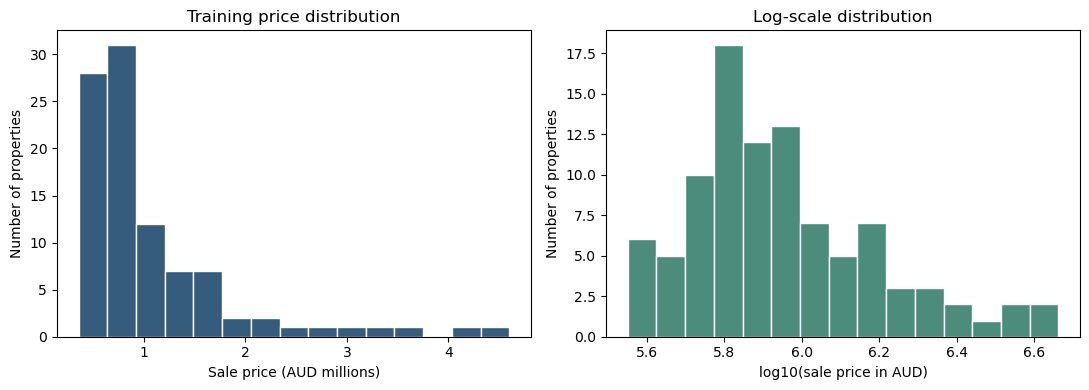

In [12]:
print(train_df['sale_price'].describe().round(0).to_string())
print('Price skewness:', round(train_df['sale_price'].skew(), 2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(train_df['sale_price'] / 1_000_000, bins=15, color='#355c7d', edgecolor='white')
axes[0].set(xlabel='Sale price (AUD millions)', ylabel='Number of properties', title='Training price distribution')
axes[1].hist(np.log10(train_df['sale_price']), bins=15, color='#4b8c7a', edgecolor='white')
axes[1].set(xlabel='log10(sale price in AUD)', ylabel='Number of properties', title='Log-scale distribution')
plt.tight_layout()
plt.show()

#### Differences between suburbs and property types

            count       mean     median     min      max
suburb                                                  
Blacktown      32   894562.0   864000.0  375000  1980000
Parramatta     32   609406.0   610000.0  355000   855000
Chatswood      32  1722583.0  1422944.0  700000  4600000


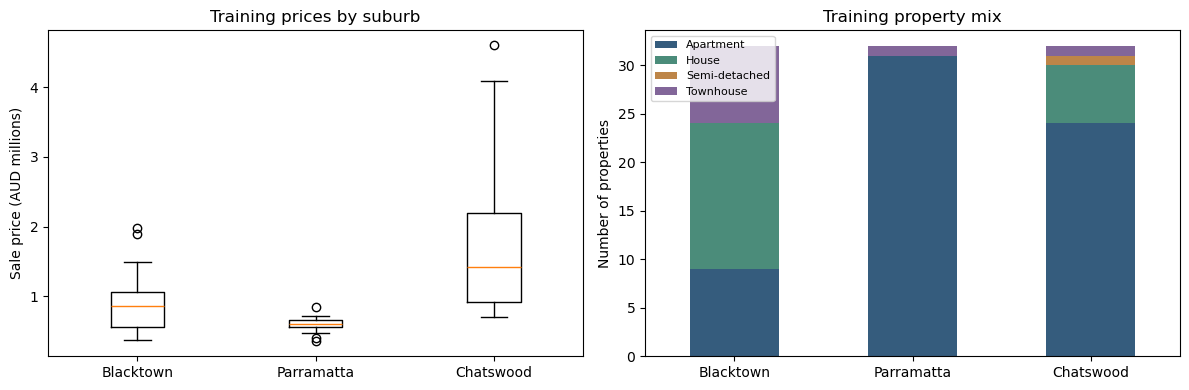


Apartment-only comparison (training):
            count     median
suburb                      
Blacktown       9   435000.0
Chatswood      24  1136540.0
Parramatta     31   610000.0


In [13]:
suburbs = ['Blacktown', 'Parramatta', 'Chatswood']
summary = train_df.groupby('suburb')['sale_price'].agg(['count', 'mean', 'median', 'min', 'max']).reindex(suburbs)
print(summary.round(0).to_string())
mix = pd.crosstab(train_df['suburb'], train_df['property_type']).reindex(suburbs, fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot([train_df.loc[train_df['suburb'] == s, 'sale_price'] / 1_000_000 for s in suburbs])
axes[0].set_xticks([1, 2, 3], suburbs)
axes[0].set(ylabel='Sale price (AUD millions)', title='Training prices by suburb')
mix.plot.bar(stacked=True, ax=axes[1], rot=0, color=['#355c7d', '#4b8c7a', '#bd8548', '#826699'])
axes[1].set(ylabel='Number of properties', xlabel='', title='Training property mix')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print('\nApartment-only comparison (training):')
print(train_df.loc[train_df['property_type'] == 'Apartment'].groupby('suburb')['sale_price'].agg(['count', 'median']).round(0).to_string())

#### Sales over time

                       count     median
sale_month suburb                      
2026-05    Chatswood      12  1442944.0
2026-06    Chatswood      13  1325000.0
2026-07    Chatswood       4  1487500.0
2026-08    Blacktown       9   805000.0
           Parramatta     16   579500.0
2026-09    Blacktown      23   900000.0
           Chatswood       3  1123080.0
           Parramatta     16   615000.0

Date coverage:
                   min        max
suburb                          
Blacktown  2026-08-21 2026-09-30
Chatswood  2026-05-07 2026-09-19
Parramatta 2026-08-21 2026-09-28


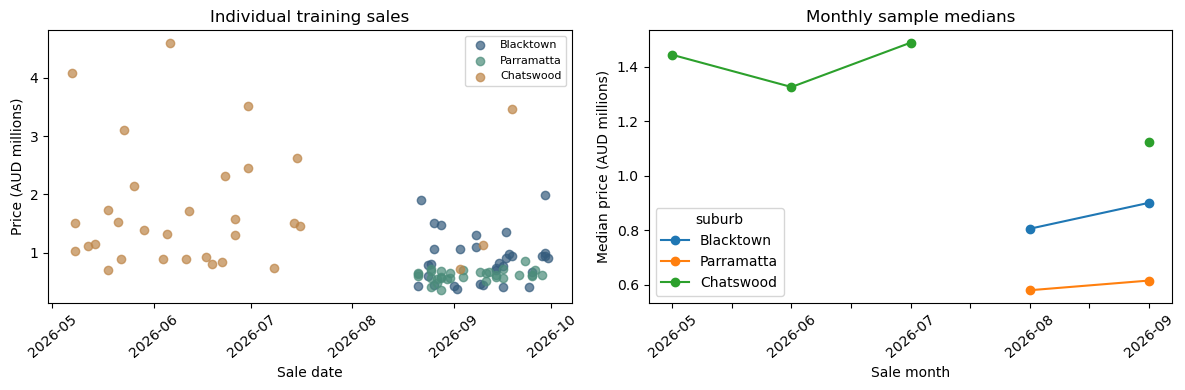

In [14]:
monthly = (train_df.assign(sale_month=train_df['sale_date'].dt.to_period('M').astype(str))
           .groupby(['sale_month', 'suburb'])['sale_price'].agg(['count', 'median']))
print(monthly.round(0).to_string())
print('\nDate coverage:\n', train_df.groupby('suburb')['sale_date'].agg(['min', 'max']).to_string())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for suburb, color in zip(suburbs, ['#355c7d', '#4b8c7a', '#bd8548']):
    subset = train_df[train_df['suburb'] == suburb]
    axes[0].scatter(subset['sale_date'], subset['sale_price'] / 1_000_000, label=suburb, alpha=0.7, color=color)
monthly['median'].unstack('suburb').reindex(columns=suburbs).div(1_000_000).plot(marker='o', ax=axes[1])
axes[0].set(title='Individual training sales', xlabel='Sale date', ylabel='Price (AUD millions)')
axes[0].legend(fontsize=8)
axes[1].set(title='Monthly sample medians', xlabel='Sale month', ylabel='Median price (AUD millions)')
for ax in axes: ax.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()

#### Relationships with numeric features

                sale_price  bedrooms  bathrooms  parking_spaces
sale_price            1.00      0.64       0.29            0.51
bedrooms              0.64      1.00       0.50            0.67
bathrooms             0.29      0.50       1.00            0.27
parking_spaces        0.51      0.67       0.27            1.00


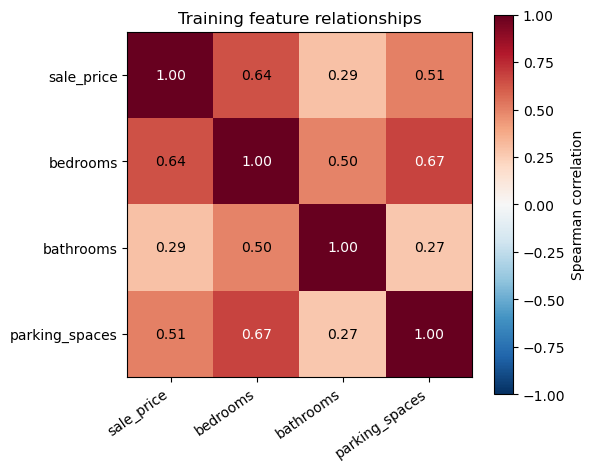

In [15]:
numeric = ['sale_price', 'bedrooms', 'bathrooms', 'parking_spaces']
correlations = train_df[numeric].corr(method='spearman')
print(correlations.round(2).to_string())
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(correlations, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(numeric)), numeric, rotation=35, ha='right')
ax.set_yticks(range(len(numeric)), numeric)
for i in range(len(numeric)):
    for j in range(len(numeric)):
        value = correlations.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='white' if abs(value) > 0.65 else 'black')
fig.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('Training feature relationships')
plt.tight_layout()
plt.show()

#### Potential outliers

In [16]:
q1, q3 = train_df['sale_price'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = train_df.loc[(train_df['sale_price'] < lower) | (train_df['sale_price'] > upper)]
print(f'IQR screening limits: AUD {lower:,.0f} to AUD {upper:,.0f}')
print('Flagged properties:', len(outliers))
print(outliers[['property_id', 'address', 'suburb', 'property_type', 'sale_price', 'bedrooms']]
      .sort_values('sale_price', ascending=False).to_string(index=False))
print('\nFive highest training prices:')
print(train_df.nlargest(5, 'sale_price')[['property_id', 'address', 'suburb', 'sale_price']].to_string(index=False))

IQR screening limits: AUD -428,125 to AUD 2,336,875
Flagged properties: 7
property_id               address    suburb property_type  sale_price  bedrooms
       C022    11 Hercules Street Chatswood         House     4600000         4
       C038     10 Holland Street Chatswood         House     4080000         3
       C010       274 High Street Chatswood         House     3510000         5
       C001   88 Hawthorne Avenue Chatswood         House     3458000         5
       C029       5 Spencer Place Chatswood         House     3100000         5
       C006 2002/1 Cambridge Lane Chatswood     Apartment     2628000         3
       C011   502/13 Oscar Street Chatswood     Apartment     2450000         3

Five highest training prices:
property_id             address    suburb  sale_price
       C022  11 Hercules Street Chatswood     4600000
       C038   10 Holland Street Chatswood     4080000
       C010     274 High Street Chatswood     3510000
       C001 88 Hawthorne Avenue Chatswo

#### Feature engineering decisions

In [20]:
baseline_features = ['suburb', 'property_type', 'bedrooms', 'bathrooms', 'parking_spaces']

def make_features(data):
    result = data[baseline_features].copy()
    result['bed_bath_interaction'] = data['bedrooms'] * data['bathrooms']
    result['sale_month_index'] = ((data['sale_date'].dt.year - 2025) * 12
                                 + data['sale_date'].dt.month - 10)
    return result

X_train = make_features(train_df)
X_test = make_features(test_df)
y_train = train_df['sale_price'].copy()
y_test = test_df['sale_price'].copy()
print(X_train.head().to_string(index=False))
print('\nTraining feature shape:', X_train.shape)
print('Held-out feature shape:', X_test.shape)


    suburb property_type  bedrooms  bathrooms  parking_spaces  bed_bath_interaction  sale_month_index
 Blacktown         House         3          2               2                     6                11
 Blacktown     Apartment         2          1               1                     2                11
Parramatta     Apartment         2          2               1                     4                11
Parramatta     Apartment         1          1               1                     1                10
Parramatta     Apartment         1          1               1                     1                10

Training feature shape: (96, 7)
Held-out feature shape: (24, 7)


### Part 3: Model Development and Evaluation

We will be making use of Linear Regression, Decision Tree Regression and Random Forest Regression. These compare a linear model, a single nonlinear tree and an ensemble.

| Model | Reason for selection | Expected limitation |
|---|---|---|
| Linear Regression | Provides a simple, interpretable baseline. Can capture additive effects of suburb, property type and room counts. | May underfit nonlinear relationships and interactions not explicitly included as features. |
| Decision Tree | Captures nonlinear relationships and combinations such as how bedroom count affects prices differently across suburbs. | Can overfit this small dataset; restricting tree depth helps control complexity. |
| Random Forest | Combines multiple trees to capture complex patterns while reducing the variability of a single tree. | Less interpretable and may struggle with rare, expensive properties or prices outside the training range. |

**Initial Expectations**
Due to less number of training data, Linear Regression will probably have limitations as it will estimate a simpler relatioship. Random Forest is expected to be the best for this experiment as prices depend on interacting property characteristics. The right-skewed prices and small number of expensive Chatswood properties could also make results sensitive to the cross-validation folds.

#### Prepare preprocessing and models

In [21]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Features already created in Part 2
categorical_features = ['suburb', 'property_type']
numeric_features = [
    'bedrooms',
    'bathrooms',
    'parking_spaces',
    'bed_bath_interaction',
    'sale_month_index'
]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        max_depth=4,
        min_samples_leaf=3,
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {
    name: Pipeline([
        ('preprocessing', clone(preprocessor)),
        ('model', model)
    ])
    for name, model in models.items()
}

#### Evaluate using five-fold cross-validation

In [22]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        error_score='raise'
    )

    train_rmse = -scores['train_RMSE'].mean()
    validation_rmse = -scores['test_RMSE'].mean()

    results.append({
        'Model': name,
        'Train RMSE': train_rmse,
        'CV RMSE': validation_rmse,
        'CV RMSE SD': scores['test_RMSE'].std(ddof=1),
        'CV MAE': -scores['test_MAE'].mean(),
        'CV R2': scores['test_R2'].mean(),
        'RMSE gap': validation_rmse - train_rmse
    })

results_df = (
    pd.DataFrame(results)
    .set_index('Model')
    .sort_values('CV RMSE')
)

print(results_df.round(2).to_string())

D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


                   Train RMSE    CV RMSE  CV RMSE SD     CV MAE  CV R2   RMSE gap
Model                                                                            
Linear Regression   370736.77  411586.71   130504.22  298901.95   0.69   40849.95
Random Forest       279951.27  441250.12   218034.42  236792.77   0.66  161298.86
Decision Tree       262620.42  498591.96   279460.70  257782.25   0.55  235971.54


D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


#### Plot performance and investigate model complexity

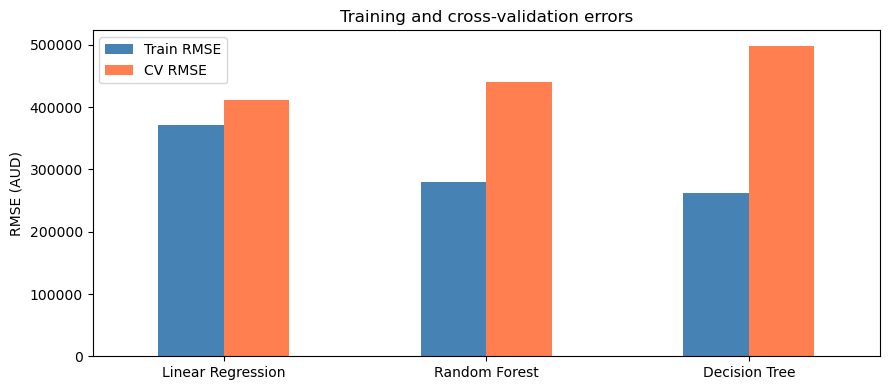

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))

results_df[['Train RMSE', 'CV RMSE']].plot(
    kind='bar',
    ax=ax,
    color=['steelblue', 'coral'],
    rot=0
)

ax.set_title('Training and cross-validation errors')
ax.set_ylabel('RMSE (AUD)')
ax.set_xlabel('')
plt.tight_layout()
plt.show()

Comparing several decision tree depths using the same folds to evaluate how performance is affected by complexity 

D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning:

           Train RMSE   CV RMSE
Depth                          
1            622286.0  798475.0
2            393079.0  598946.0
3            284751.0  490815.0
4            262620.0  498592.0
6            256942.0  497321.0
8            256353.0  497932.0
Unlimited    256353.0  500958.0


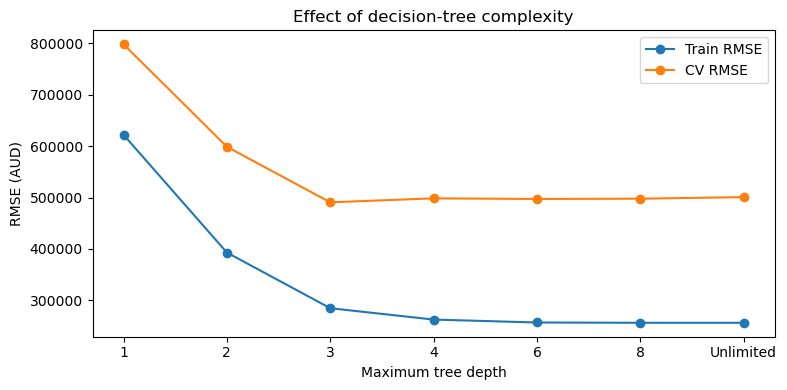

In [24]:

depth_results = []

for depth in [1, 2, 3, 4, 6, 8, None]:
    pipeline = clone(pipelines['Decision Tree'])
    pipeline.set_params(model__max_depth=depth)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring='neg_root_mean_squared_error',
        return_train_score=True,
        error_score='raise'
    )

    depth_results.append({
        'Depth': str(depth) if depth is not None else 'Unlimited',
        'Train RMSE': -scores['train_score'].mean(),
        'CV RMSE': -scores['test_score'].mean()
    })

depth_df = pd.DataFrame(depth_results).set_index('Depth')
print(depth_df.round(0).to_string())

depth_df.plot(marker='o', figsize=(8, 4))
plt.xlabel('Maximum tree depth')
plt.ylabel('RMSE (AUD)')
plt.title('Effect of decision-tree complexity')
plt.tight_layout()
plt.show()

#### Examine prediction errors

D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
D:\Program_Files\Anaconda\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


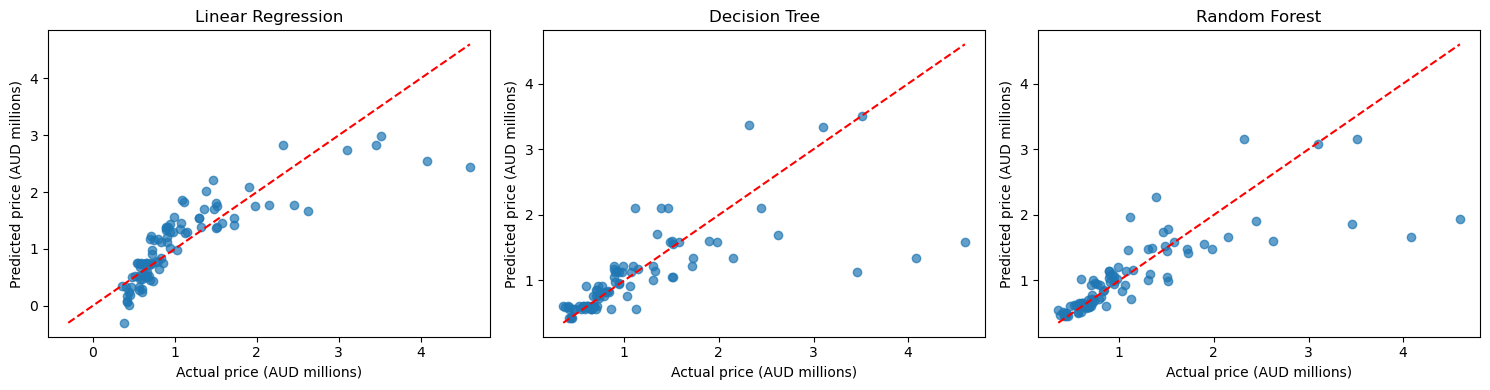

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
oof_predictions = {}

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    predictions = cross_val_predict(
        pipeline, X_train, y_train, cv=cv
    )
    oof_predictions[name] = predictions

    ax.scatter(
        y_train / 1_000_000,
        predictions / 1_000_000,
        alpha=0.7
    )

    lower = min(y_train.min(), predictions.min()) / 1_000_000
    upper = max(y_train.max(), predictions.max()) / 1_000_000

    ax.plot([lower, upper], [lower, upper], 'r--')
    ax.set_title(name)
    ax.set_xlabel('Actual price (AUD millions)')
    ax.set_ylabel('Predicted price (AUD millions)')

plt.tight_layout()
plt.show()

#### Select the model and evaluate the held-out test set

In [26]:
best_name = results_df.index[0]
best_model = clone(pipelines[best_name])

best_model.fit(X_train, y_train)
test_predictions = best_model.predict(X_test)

print('Selected model:', best_name)
print(f'Test MAE: AUD {mean_absolute_error(y_test, test_predictions):,.0f}')
print(
    f'Test RMSE: AUD '
    f'{np.sqrt(mean_squared_error(y_test, test_predictions)):,.0f}'
)
print(f'Test R²: {r2_score(y_test, test_predictions):.3f}')

test_errors = test_df[
    ['suburb', 'property_type', 'sale_price']
].copy()

test_errors['predicted_price'] = test_predictions
test_errors['absolute_error'] = np.abs(
    test_errors['sale_price'] - test_predictions
)

print('\nTest errors by suburb:')
print(
    test_errors.groupby('suburb')['absolute_error']
    .agg(['count', 'mean'])
    .round(0)
    .to_string()
)

Selected model: Linear Regression
Test MAE: AUD 286,929
Test RMSE: AUD 435,303
Test R²: 0.837

Test errors by suburb:
            count      mean
suburb                     
Blacktown       8  279426.0
Chatswood       8  495791.0
Parramatta      8   85569.0


### Part 4: Investigating Prediction Failures

In [27]:
# Investigate errors from the selected model on the held-out test set
error_analysis = test_df.copy()
error_analysis['predicted_price'] = best_model.predict(X_test)

# Positive error = overprediction; negative error = underprediction
error_analysis['signed_error'] = ( error_analysis['predicted_price'] - error_analysis['sale_price'])
error_analysis['absolute_error'] = error_analysis['signed_error'].abs()
error_analysis['percentage_error'] = (error_analysis['absolute_error'] / error_analysis['sale_price'] * 100)
error_analysis['direction'] = np.where( error_analysis['signed_error'] > 0,'Overprediction','Underprediction')

top5_errors = error_analysis.nlargest(5, 'absolute_error').copy()

columns = [
    'address', 'suburb', 'property_type',
    'bedrooms', 'bathrooms', 'parking_spaces',
    'sale_price', 'predicted_price',
    'absolute_error', 'percentage_error', 'direction'
]

print(top5_errors[columns].round(2).to_string(index=False))

# Inspect available contextual information for each property
for _, row in top5_errors.iterrows():
    print(f"\n{row['address']}, {row['suburb']}")
    print('Sale date:', row['sale_date'].date())
    print('Property notes:', row['property_notes'])
    print('Reported area:', row['reported_area_m2'])
    print('Area note:', row['area_note'])
    print('Source:', row['source_url'])

                  address    suburb property_type  bedrooms  bathrooms  parking_spaces  sale_price  predicted_price  absolute_error  percentage_error       direction
          8 Claude Street Chatswood         House         3          1               2     3950000       2533046.93      1416953.07             35.87 Underprediction
          31 Royal Street Chatswood         House         5          3               1     4180000       3105482.93      1074517.07             25.71 Underprediction
        202/2 Oliver Road Chatswood     Apartment         2          2               1     1100000       1550604.18       450604.18             40.96  Overprediction
84-84a Duckmallois Avenue Blacktown         House         6          3               3     1405000       1847206.64       442206.64             31.47  Overprediction
         178 Fullers Road Chatswood         House         4          2               2     2450000       2868114.38       418114.38             17.07  Overprediction

8 C

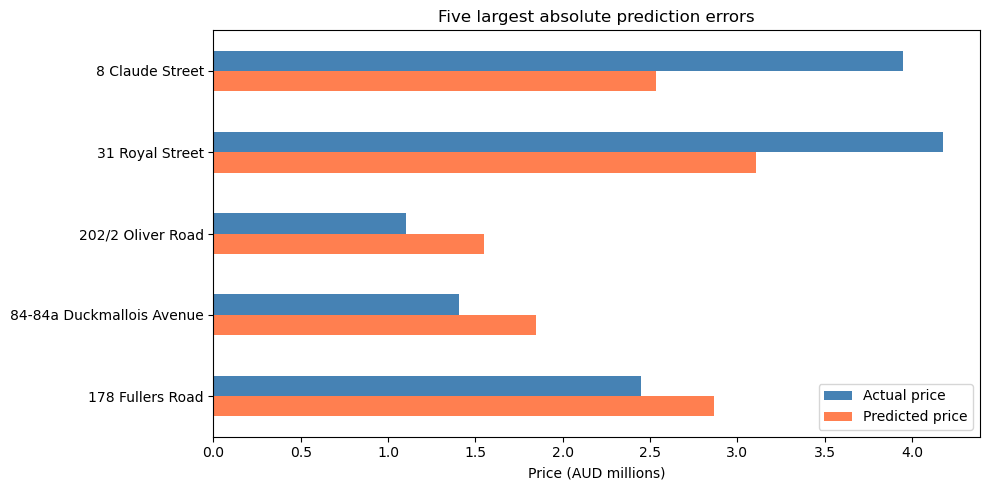

In [28]:
# Compare actual and predicted prices
comparison = top5_errors.set_index('address')[
    ['sale_price', 'predicted_price']
].div(1_000_000)

comparison.columns = ['Actual price', 'Predicted price']

ax = comparison.plot(
    kind='barh',
    figsize=(10, 5),
    color=['steelblue', 'coral']
)
ax.invert_yaxis()
ax.set_xlabel('Price (AUD millions)')
ax.set_ylabel('')
ax.set_title('Five largest absolute prediction errors')
plt.tight_layout()
plt.show()

### Part 5: Human Judgement, Machine Learning, and Large Language Models

#### Selecting ten properties and prepare identical information

In [29]:
# Excludes the five properties already investigated in Part 4
remaining_test = test_df.drop(index=top5_errors.index)

selected10 = remaining_test.sample(n=10, random_state=42).copy()

# Using exactly the same predictors as the ML model
valuation_inputs = make_features(selected10).reset_index(drop=True)

case_ids = [f'P{i:02d}' for i in range(1, 11)]
valuation_inputs.insert(0, 'case_id', case_ids)

print('Information for human and LLM estimates:')
print(valuation_inputs.to_string(index=False))

Information for human and LLM estimates:
case_id     suburb property_type  bedrooms  bathrooms  parking_spaces  bed_bath_interaction  sale_month_index
    P01 Parramatta     Apartment         1          1               1                     1                11
    P02  Blacktown     Apartment         2          2               1                     4                10
    P03 Parramatta     Apartment         2          2               1                     4                11
    P04  Chatswood     Apartment         1          1               1                     1                11
    P05  Blacktown     Townhouse         3          1               1                     3                11
    P06  Blacktown         House         5          3               6                    15                11
    P07  Blacktown         House         3          1               1                     3                11
    P08 Parramatta     Apartment         2          2               1          

In [31]:
llm_estimates = [
    560000,
    780000,
    820000,
    710000,
    930000,
    1750000,
    950000,
    830000,
    3000000,
    1000000
]

In [32]:
human_estimates=[
    500000,
    600000,
    800000,
    800000,
    900000,
    950000,
    850000,
    800000,
    2500000,
    950000
]

#### Comparing all predictions to actual prices

In [33]:
human_values = np.asarray(human_estimates, dtype=float)
llm_values = np.asarray(llm_estimates, dtype=float)

if (
    human_values.shape != (10,)
    or llm_values.shape != (10,)
    or not np.isfinite(human_values).all()
    or not np.isfinite(llm_values).all()
    or (human_values <= 0).any()
    or (llm_values <= 0).any()
):
    raise ValueError('Enter ten valid positive prices for each approach.')

comparison = selected10[
    ['suburb', 'property_type', 'bedrooms', 'bathrooms',
     'parking_spaces', 'sale_price']
].reset_index(drop=True)

comparison.insert(0, 'case_id', case_ids)
comparison = comparison.rename(columns={'sale_price': 'Actual'})

comparison['ML'] = best_model.predict(make_features(selected10))
comparison['LLM'] = llm_values
comparison['Human'] = human_values

for approach in ['ML', 'LLM', 'Human']:
    comparison[f'{approach} absolute error'] = (
        comparison[approach] - comparison['Actual']
    ).abs()

    comparison[f'{approach} error %'] = (
        comparison[f'{approach} absolute error']
        / comparison['Actual'] * 100
    )

print('Predictions:')
print(comparison[
    ['case_id', 'suburb', 'property_type',
     'Actual', 'ML', 'LLM', 'Human']
].round(0).to_string(index=False))

print('\nErrors:')
print(comparison[
    ['case_id',
     'ML absolute error', 'LLM absolute error', 'Human absolute error',
     'ML error %', 'LLM error %', 'Human error %']
].round(2).to_string(index=False))

metrics = []

for approach in ['ML', 'LLM', 'Human']:
    actual = comparison['Actual']
    predicted = comparison[approach]

    metrics.append({
        'Approach': approach,
        'MAE (AUD)': mean_absolute_error(actual, predicted),
        'RMSE (AUD)': np.sqrt(mean_squared_error(actual, predicted)),
        'MAPE (%)': np.mean(np.abs((actual - predicted) / actual)) * 100,
        'R2': r2_score(actual, predicted),
        'Mean signed error (AUD)': np.mean(predicted - actual)
    })

metrics_df = (
    pd.DataFrame(metrics)
    .set_index('Approach')
    .sort_values('RMSE (AUD)')
)

print('\nOverall comparison:')
print(metrics_df.round(2).to_string())

Predictions:
case_id     suburb property_type  Actual        ML       LLM     Human
    P01 Parramatta     Apartment  547000  289033.0  560000.0  500000.0
    P02  Blacktown     Apartment  481000  234089.0  780000.0  600000.0
    P03 Parramatta     Apartment  700000  710724.0  820000.0  800000.0
    P04  Chatswood     Apartment  745000 1052078.0  710000.0  800000.0
    P05  Blacktown     Townhouse  745000  691333.0  930000.0  900000.0
    P06  Blacktown         House 1260000 1633046.0 1750000.0  950000.0
    P07  Blacktown         House 1600000 1243874.0  950000.0  850000.0
    P08 Parramatta     Apartment  640000  710724.0  830000.0  800000.0
    P09  Chatswood         House 2420000 2533047.0 3000000.0 2500000.0
    P10  Blacktown         House 1105000 1189189.0 1000000.0  950000.0

Errors:
case_id  ML absolute error  LLM absolute error  Human absolute error  ML error %  LLM error %  Human error %
    P01          257966.84             13000.0               47000.0       47.16        

#### Comparison Plots

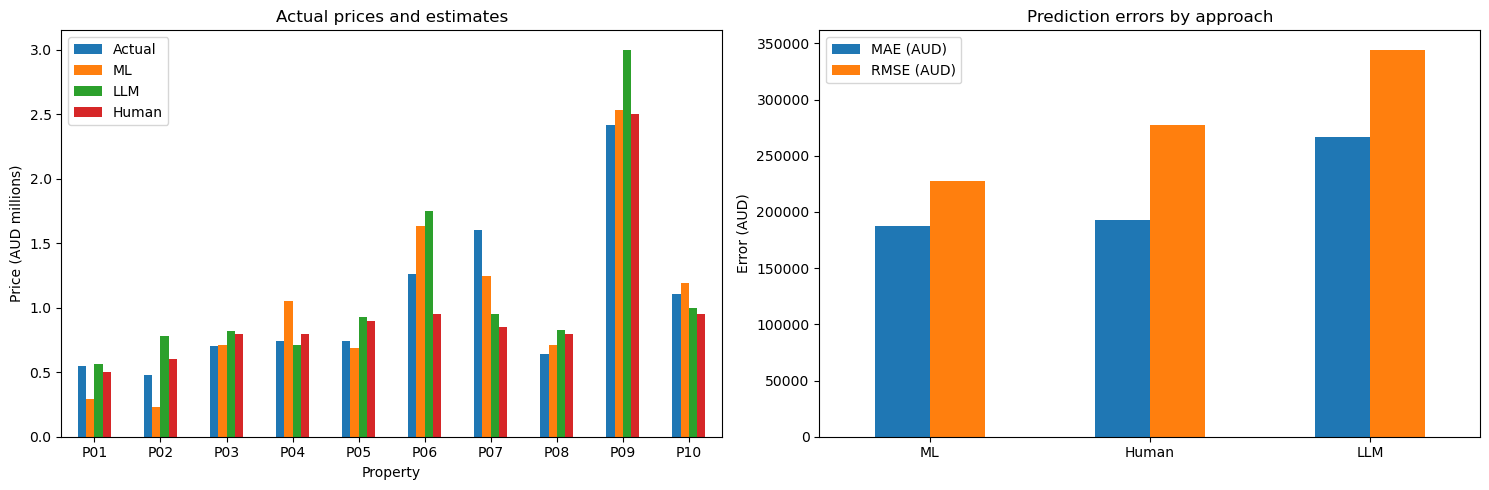

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comparison.set_index('case_id')[
    ['Actual', 'ML', 'LLM', 'Human']
].div(1_000_000).plot.bar(ax=axes[0], rot=0)

axes[0].set_title('Actual prices and estimates')
axes[0].set_xlabel('Property')
axes[0].set_ylabel('Price (AUD millions)')

metrics_df[['MAE (AUD)', 'RMSE (AUD)']].plot.bar(
    ax=axes[1], rot=0
)

axes[1].set_title('Prediction errors by approach')
axes[1].set_xlabel('')
axes[1].set_ylabel('Error (AUD)')

plt.tight_layout()
plt.show()